# best_final

동일 전처리(0.1755 기준) + Optuna(XGBoost/RandomForest) + CatBoost 최고점 파라미터 + OOF 앙상블

## 1) 환경 설정 및 라이브러리 임포트

In [1]:
import os
import json
import random
import warnings
from pathlib import Path

import joblib
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
from catboost import CatBoostClassifier

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

N_SPLITS = 5
N_TRIALS_XGB = 25
N_TRIALS_RF = 25
N_TRIALS_CAT = 20
TUNE_SPLITS = 3
TUNE_SAMPLE_SIZE = 120000
RUN_CAT_OPTUNA = False

DATA_DIR = Path(".")
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_SUB_PATH = DATA_DIR / "sample_submission.csv"

print("seed:", SEED)
print("optuna trials:", {"xgb": N_TRIALS_XGB, "rf": N_TRIALS_RF, "cat": N_TRIALS_CAT})

seed: 42
optuna trials: {'xgb': 25, 'rf': 25, 'cat': 20}


## 2) 데이터 로드 및 기본 검증

In [2]:
train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

print("train shape:", train_raw.shape)
print("test shape :", test_raw.shape)
print("target mean:", train_raw["fraud_bool"].mean())
print("missing(train) top10:")
print(train_raw.isna().sum().sort_values(ascending=False).head(10))

train shape: (700000, 33)
test shape : (300000, 32)
target mean: 0.010917142857142858
missing(train) top10:
id                   0
fraud_bool           0
yearly_income        0
name_email_sim       0
prev_addr_months     0
curr_addr_months     0
age_bucket           0
days_since_req       0
init_transfer_amt    0
payment_type         0
dtype: int64


## 3) 공통 전처리 파이프라인 정의 (0.1755 동일 전처리)

`baseline_run_hyperparams.json`의 로그와 상수에 맞춘 동일 변환입니다.

In [3]:
def preprocess_like_1755(train_df: pd.DataFrame, test_df: pd.DataFrame):
    train = train_df.copy()
    test = test_df.copy()

    _WPM = 52.0 / 12.0
    _HPW = 24.0 * 7.0

    # 1) credit_risk_score
    CRS = "credit_risk_score"
    if CRS in train.columns:
        train[CRS] = train[CRS].clip(lower=0)
        test[CRS] = test[CRS].clip(lower=0)

    # 2) yearly_income low/high flags
    YI = "yearly_income"
    if YI in train.columns:
        q10 = train[YI].quantile(0.1)
        q90 = train[YI].quantile(0.9)
        train["yearly_income_low10"] = (train[YI] <= q10).astype(np.int8)
        train["yearly_income_high10"] = (train[YI] >= q90).astype(np.int8)
        test["yearly_income_low10"] = (test[YI] <= q10).astype(np.int8)
        test["yearly_income_high10"] = (test[YI] >= q90).astype(np.int8)

    # 3) name_email_sim clip + flag
    NES = "name_email_sim"
    if NES in train.columns:
        train[NES] = train[NES].clip(0, 1)
        test[NES] = test[NES].clip(0, 1)
        train["name_email_low_sim"] = (train[NES] <= 0.3).astype(np.int8)
        test["name_email_low_sim"] = (test[NES] <= 0.3).astype(np.int8)

    # 4) curr_addr_months: -1 impute, month->week, short flag, log1p
    CAM = "curr_addr_months"
    if CAM in train.columns:
        cam_med = train.loc[train[CAM] != -1, CAM].median()
        train["curr_addr_missing"] = (train[CAM] == -1).astype(np.int8)
        test["curr_addr_missing"] = (test[CAM] == -1).astype(np.int8)
        train[CAM] = train[CAM].where(train[CAM] != -1, cam_med)
        test[CAM] = test[CAM].where(test[CAM] != -1, cam_med)
        train[CAM] = train[CAM] * _WPM
        test[CAM] = test[CAM] * _WPM
        cam_cut = float(train[CAM].quantile(0.25))
        train["curr_addr_short"] = (train[CAM] <= cam_cut).astype(np.int8)
        test["curr_addr_short"] = (test[CAM] <= cam_cut).astype(np.int8)
        train[CAM] = np.log1p(train[CAM].clip(lower=0))
        test[CAM] = np.log1p(test[CAM].clip(lower=0))

    # 5) init_transfer_amt: negative -> high-amount mean
    ITA = "init_transfer_amt"
    if ITA in train.columns:
        pos = train.loc[train[ITA] > 0, ITA]
        q90p = pos.quantile(0.9)
        large_mean = train.loc[train[ITA] >= q90p, ITA].mean()
        train[ITA] = np.where(train[ITA] < 0, large_mean, train[ITA])
        test[ITA] = np.where(test[ITA] < 0, large_mean, test[ITA])

    # 6) req_credit_limit: clip + log1p
    RCL = "req_credit_limit"
    if RCL in train.columns:
        rlo = float(train[RCL].quantile(0.005))
        rhi = float(train[RCL].quantile(0.995))
        train[RCL] = np.log1p(train[RCL].clip(rlo, rhi))
        test[RCL] = np.log1p(test[RCL].clip(rlo, rhi))

    # 7) session_length_min: clip>=0, winsor, log1p
    SLM = "session_length_min"
    if SLM in train.columns:
        train[SLM] = train[SLM].clip(lower=0)
        test[SLM] = test[SLM].clip(lower=0)
        sl_lo = float(train[SLM].quantile(0.005))
        sl_hi = float(train[SLM].quantile(0.995))
        train[SLM] = np.log1p(train[SLM].clip(sl_lo, sl_hi))
        test[SLM] = np.log1p(test[SLM].clip(sl_lo, sl_hi))

    # 8) days_since_req: within_7 flag + days->weeks + clip + log1p
    DSR = "days_since_req"
    if DSR in train.columns:
        train["days_req_within_7"] = (train[DSR] <= 7).astype(np.int8)
        test["days_req_within_7"] = (test[DSR] <= 7).astype(np.int8)
        dsr_hi = float(train[DSR].quantile(0.99))
        train[DSR] = np.log1p((train[DSR].clip(lower=0, upper=dsr_hi)) / 7.0)
        test[DSR] = np.log1p((test[DSR].clip(lower=0, upper=dsr_hi)) / 7.0)

    # 9) req_rate_6h/24h/4w: clip + *168 + log1p
    for c in ["req_rate_6h", "req_rate_24h", "req_rate_4w"]:
        if c in train.columns:
            train[c] = np.log1p(train[c].clip(lower=0) * _HPW)
            test[c] = np.log1p(test[c].clip(lower=0) * _HPW)

    # 10) zip_req_count_4w: /4 + flag + log1p
    ZIP = "zip_req_count_4w"
    if ZIP in train.columns:
        train[ZIP] = train[ZIP] / 4.0
        test[ZIP] = test[ZIP] / 4.0
        train["zip_req_gt_0"] = (train[ZIP] > 0).astype(np.int8)
        test["zip_req_gt_0"] = (test[ZIP] > 0).astype(np.int8)
        train[ZIP] = np.log1p(train[ZIP].clip(lower=0))
        test[ZIP] = np.log1p(test[ZIP].clip(lower=0))

    # 11) branch_req_count_8w: /8 + flag + log1p
    BR = "branch_req_count_8w"
    if BR in train.columns:
        train[BR] = train[BR] / 8.0
        test[BR] = test[BR] / 8.0
        train["branch_req_gt_0"] = (train[BR] > 0).astype(np.int8)
        test["branch_req_gt_0"] = (test[BR] > 0).astype(np.int8)
        train[BR] = np.log1p(train[BR].clip(lower=0))
        test[BR] = np.log1p(test[BR].clip(lower=0))

    # 12) bank_months_count: -1 median + month->week
    BMC = "bank_months_count"
    if BMC in train.columns:
        bmc_med = train.loc[train[BMC] != -1, BMC].median()
        train["bank_months_missing"] = (train[BMC] == -1).astype(np.int8)
        test["bank_months_missing"] = (test[BMC] == -1).astype(np.int8)
        train[BMC] = train[BMC].where(train[BMC] != -1, bmc_med) * _WPM
        test[BMC] = test[BMC].where(test[BMC] != -1, bmc_med) * _WPM

    # 13) prev_addr_months: -1 median + month->week + log1p + flag
    PAM = "prev_addr_months"
    if PAM in train.columns:
        pam_med = train.loc[train[PAM] != -1, PAM].median()
        train["prev_addr_missing"] = (train[PAM] == -1).astype(np.int8)
        test["prev_addr_missing"] = (test[PAM] == -1).astype(np.int8)
        train[PAM] = train[PAM].where(train[PAM] != -1, pam_med) * _WPM
        test[PAM] = test[PAM].where(test[PAM] != -1, pam_med) * _WPM
        train[PAM] = np.log1p(train[PAM].clip(lower=0))
        test[PAM] = np.log1p(test[PAM].clip(lower=0))

    # 14) dob_email_count_4w: /4 + z_age + outlier + log1p
    DEC = "dob_email_count_4w"
    if DEC in train.columns:
        train[DEC] = train[DEC] / 4.0
        test[DEC] = test[DEC] / 4.0
        gm = float(train[DEC].mean())
        gs = max(float(train[DEC].std()), 1e-6)
        d99 = float(train[DEC].quantile(0.99))
        train["dob_email_z_age"] = ((train[DEC] - gm) / gs).astype(np.float32)
        test["dob_email_z_age"] = ((test[DEC] - gm) / gs).astype(np.float32)
        train["dob_email_hi_outlier"] = (train[DEC] > d99).astype(np.int8)
        test["dob_email_hi_outlier"] = (test[DEC] > d99).astype(np.int8)
        train[DEC] = np.log1p(train[DEC].clip(lower=0))
        test[DEC] = np.log1p(test[DEC].clip(lower=0))

    # 15) month_idx -> sin/cos (period=8)
    if "month_idx" in train.columns:
        nm = 8.0
        ts = train["month_idx"].astype(float)
        ss = test["month_idx"].astype(float)
        train["month_sin"] = np.sin(2 * np.pi * ts / nm).astype(np.float32)
        train["month_cos"] = np.cos(2 * np.pi * ts / nm).astype(np.float32)
        test["month_sin"] = np.sin(2 * np.pi * ss / nm).astype(np.float32)
        test["month_cos"] = np.cos(2 * np.pi * ss / nm).astype(np.float32)
        train = train.drop(columns=["month_idx"])
        test = test.drop(columns=["month_idx"])

    target_col = "fraud_bool"
    drop_cols = ["id", target_col]
    drop_features = ["device_fraud_history"]

    # 16) age_bucket one-hot
    if "age_bucket" in train.columns:
        train = pd.get_dummies(train, columns=["age_bucket"], prefix="age_bkt", dummy_na=False)
        test = pd.get_dummies(test, columns=["age_bucket"], prefix="age_bkt", dummy_na=False)

    # 17) object one-hot
    obj_cols = [c for c in train.columns if c not in [target_col] and train[c].dtype == "object"]
    if obj_cols:
        train = pd.get_dummies(train, columns=obj_cols, dummy_na=False)
        test = pd.get_dummies(test, columns=obj_cols, dummy_na=False)

    X = train.drop(columns=[c for c in drop_cols if c in train.columns], errors="ignore")
    X = X.drop(columns=[c for c in drop_features if c in X.columns], errors="ignore")
    y = train[target_col].astype(np.int8)

    X_test = test.drop(columns=[c for c in ["id"] if c in test.columns], errors="ignore")
    X_test = X_test.drop(columns=[c for c in drop_features if c in X_test.columns], errors="ignore")

    X, X_test = X.align(X_test, join="left", axis=1, fill_value=0)

    X = X.astype(np.float32)
    X_test = X_test.astype(np.float32)

    preprocess_meta = {
        "seed": SEED,
        "target_col": target_col,
        "drop_features": drop_features,
        "n_features": int(X.shape[1]),
        "feature_list": X.columns.tolist(),
    }
    return X, y, X_test, preprocess_meta


X, y, X_test, preprocess_meta = preprocess_like_1755(train_raw, test_raw)
print("X shape:", X.shape, "| X_test shape:", X_test.shape)
print("Fraud ratio:", y.mean())

X shape: (700000, 72) | X_test shape: (300000, 72)
Fraud ratio: 0.010917142857142858


## 4) 학습/검증 분할 및 평가 지표 설정

In [4]:
cv5 = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_tune = StratifiedKFold(n_splits=TUNE_SPLITS, shuffle=True, random_state=SEED)


def ap_score(y_true, y_prob):
    return average_precision_score(y_true, y_prob)


if len(X) > TUNE_SAMPLE_SIZE:
    rs = np.random.RandomState(SEED)
    idx = rs.choice(len(X), size=TUNE_SAMPLE_SIZE, replace=False)
    X_tune = X.iloc[idx].reset_index(drop=True)
    y_tune = y.iloc[idx].reset_index(drop=True)
else:
    X_tune = X.copy()
    y_tune = y.copy()

# 동일 전처리 결과(X, X_test)를 모든 모델에 공통 적용하기 위한 파이프라인 래퍼
numeric_cols = X.columns.tolist()
common_transformer = ColumnTransformer(
    transformers=[("num", "passthrough", numeric_cols)],
    remainder="drop",
)
common_pipeline = Pipeline([
    ("identity", FunctionTransformer(lambda z: z, validate=False)),
])

print("tuning sample:", X_tune.shape)
print("common transformer columns:", len(numeric_cols))

tuning sample: (120000, 72)
common transformer columns: 72


## 5) Optuna Objective 함수 구성: XGBoost

In [5]:
def xgb_objective(trial):
    params = {
        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "n_estimators": trial.suggest_int("n_estimators", 300, 1800),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 80),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "scale_pos_weight": float((y_tune == 0).sum() / max((y_tune == 1).sum(), 1)),
        "random_state": SEED,
        "n_jobs": -1,
        "tree_method": "hist",
    }

    fold_scores = []
    for tr_idx, va_idx in cv_tune.split(X_tune, y_tune):
        X_tr, X_va = X_tune.iloc[tr_idx], X_tune.iloc[va_idx]
        y_tr, y_va = y_tune.iloc[tr_idx], y_tune.iloc[va_idx]
        clf = xgb.XGBClassifier(**params)
        clf.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        pred = clf.predict_proba(X_va)[:, 1]
        fold_scores.append(ap_score(y_va, pred))

    return float(np.mean(fold_scores))

## 6) XGBoost 하이퍼파라미터 최적화 및 최고 모델 학습

In [6]:
study_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(xgb_objective, n_trials=N_TRIALS_XGB, show_progress_bar=True)

best_xgb_params = study_xgb.best_trial.params.copy()
best_xgb_params.update({
    "objective": "binary:logistic",
    "eval_metric": "aucpr",
    "scale_pos_weight": float((y == 0).sum() / max((y == 1).sum(), 1)),
    "random_state": SEED,
    "n_jobs": -1,
    "tree_method": "hist",
})

xgb_oof = np.zeros(len(X), dtype=np.float64)
xgb_test = np.zeros(len(X_test), dtype=np.float64)
xgb_fold = []

for fold, (tr_idx, va_idx) in enumerate(cv5.split(X, y), start=1):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
    model = xgb.XGBClassifier(**best_xgb_params)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    va_pred = model.predict_proba(X_va)[:, 1]
    te_pred = model.predict_proba(X_test)[:, 1]
    xgb_oof[va_idx] = va_pred
    xgb_test += te_pred / N_SPLITS
    xgb_fold.append(ap_score(y_va, va_pred))

xgb_oof_ap = ap_score(y, xgb_oof)
print("XGB best params:", study_xgb.best_trial.params)
print(f"XGB OOF AP: {xgb_oof_ap:.6f} | fold mean/std: {np.mean(xgb_fold):.6f}/{np.std(xgb_fold):.6f}")

[I 2026-03-27 00:55:18,996] A new study created in memory with name: no-name-c0d89279-6da6-49a2-9066-b6630e24afd8


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-03-27 00:57:22,904] Trial 0 finished with value: 0.1171562619199863 and parameters: {'learning_rate': 0.047377279007281566, 'max_depth': 10, 'n_estimators': 1398, 'min_child_weight': 48, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 0.00019517224641449495, 'reg_lambda': 2.1423021757741068}. Best is trial 0 with value: 0.1171562619199863.
[I 2026-03-27 00:57:52,040] Trial 1 finished with value: 0.1260193909723177 and parameters: {'learning_rate': 0.0798261175712336, 'max_depth': 8, 'n_estimators': 330, 'min_child_weight': 78, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_alpha': 0.0008111941985431928, 'reg_lambda': 0.0008260808399079611}. Best is trial 1 with value: 0.1260193909723177.
[I 2026-03-27 00:59:11,493] Trial 2 finished with value: 0.11600985309275251 and parameters: {'learning_rate': 0.04029695576831731, 'max_depth': 7, 'n_estimators': 948, 'min_child_weight': 24, 'subsample': 0.8447411578889518, '

## 7) Optuna Objective 함수 구성: RandomForest

In [7]:
def rf_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1200),
        "max_depth": trial.suggest_int("max_depth", 4, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
        "class_weight": "balanced",
        "random_state": SEED,
        "n_jobs": -1,
    }

    fold_scores = []
    for tr_idx, va_idx in cv_tune.split(X_tune, y_tune):
        X_tr, X_va = X_tune.iloc[tr_idx], X_tune.iloc[va_idx]
        y_tr, y_va = y_tune.iloc[tr_idx], y_tune.iloc[va_idx]
        clf = RandomForestClassifier(**params)
        clf.fit(X_tr, y_tr)
        pred = clf.predict_proba(X_va)[:, 1]
        fold_scores.append(ap_score(y_va, pred))

    return float(np.mean(fold_scores))

## 8) RandomForest 하이퍼파라미터 최적화 및 최고 모델 학습

In [8]:
study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(rf_objective, n_trials=N_TRIALS_RF, show_progress_bar=True)

best_rf_params = study_rf.best_trial.params.copy()
best_rf_params.update({
    "class_weight": "balanced",
    "random_state": SEED,
    "n_jobs": -1,
})

rf_oof = np.zeros(len(X), dtype=np.float64)
rf_test = np.zeros(len(X_test), dtype=np.float64)
rf_fold = []

for fold, (tr_idx, va_idx) in enumerate(cv5.split(X, y), start=1):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
    model = RandomForestClassifier(**best_rf_params)
    model.fit(X_tr, y_tr)
    va_pred = model.predict_proba(X_va)[:, 1]
    te_pred = model.predict_proba(X_test)[:, 1]
    rf_oof[va_idx] = va_pred
    rf_test += te_pred / N_SPLITS
    rf_fold.append(ap_score(y_va, va_pred))

rf_oof_ap = ap_score(y, rf_oof)
print("RF best params:", study_rf.best_trial.params)
print(f"RF OOF AP: {rf_oof_ap:.6f} | fold mean/std: {np.mean(rf_fold):.6f}/{np.std(rf_fold):.6f}")

[I 2026-03-27 01:27:02,614] A new study created in memory with name: no-name-a61e5d29-65db-4d8a-b752-634f83c9cb55


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-03-27 01:27:42,803] Trial 0 finished with value: 0.13155040397220855 and parameters: {'n_estimators': 574, 'max_depth': 29, 'min_samples_split': 23, 'min_samples_leaf': 12, 'max_features': 'sqrt', 'bootstrap': True}. Best is trial 0 with value: 0.13155040397220855.
[I 2026-03-27 01:28:22,117] Trial 1 finished with value: 0.11907478178318205 and parameters: {'n_estimators': 908, 'max_depth': 4, 'min_samples_split': 30, 'min_samples_leaf': 17, 'max_features': 'sqrt', 'bootstrap': False}. Best is trial 0 with value: 0.13155040397220855.
[I 2026-03-27 01:33:46,835] Trial 2 finished with value: 0.09542806781982373 and parameters: {'n_estimators': 632, 'max_depth': 11, 'min_samples_split': 19, 'min_samples_leaf': 3, 'max_features': None, 'bootstrap': True}. Best is trial 0 with value: 0.13155040397220855.
[I 2026-03-27 01:40:43,305] Trial 3 finished with value: 0.10274156607292188 and parameters: {'n_estimators': 714, 'max_depth': 19, 'min_samples_split': 3, 'min_samples_leaf': 13, '

## 9) Optuna Objective 함수 구성: CatBoost

In [9]:
def cat_objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 800, 2500),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "depth": trial.suggest_int("depth", 3, 8),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 30.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.1, 5.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 5.0),
        "border_count": trial.suggest_int("border_count", 32, 255),
        "loss_function": "Logloss",
        "eval_metric": "PRAUC",
        "random_seed": SEED,
        "auto_class_weights": "Balanced",
        "verbose": False,
    }

    fold_scores = []
    for tr_idx, va_idx in cv_tune.split(X_tune, y_tune):
        X_tr, X_va = X_tune.iloc[tr_idx], X_tune.iloc[va_idx]
        y_tr, y_va = y_tune.iloc[tr_idx], y_tune.iloc[va_idx]
        clf = CatBoostClassifier(**params)
        clf.fit(X_tr, y_tr, eval_set=(X_va, y_va), verbose=False)
        pred = clf.predict_proba(X_va)[:, 1]
        fold_scores.append(ap_score(y_va, pred))

    return float(np.mean(fold_scores))

## 10) CatBoost 하이퍼파라미터 최적화 및 최고 점수 모델 학습

In [10]:
cat_fixed_best_params = {
    "iterations": 2000,
    "learning_rate": 0.040331443383617174,
    "depth": 4,
    "l2_leaf_reg": 8.234548958371454,
    "random_strength": 0.514960710230099,
    "border_count": 87,
    "subsample": 0.8233119185389446,
    "bootstrap_type": "Bernoulli",
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "random_seed": 42,
    "early_stopping_rounds": 50,
    "auto_class_weights": "Balanced",
    "verbose": False,
}

if RUN_CAT_OPTUNA:
    study_cat = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study_cat.optimize(cat_objective, n_trials=N_TRIALS_CAT, show_progress_bar=True)
    cat_params = study_cat.best_trial.params.copy()
    cat_params.update({
        "loss_function": "Logloss",
        "eval_metric": "PRAUC",
        "random_seed": 42,
        "early_stopping_rounds": 50,
        "auto_class_weights": "Balanced",
        "verbose": False,
    })
else:
    study_cat = None
    cat_params = cat_fixed_best_params.copy()

cat_oof = np.zeros(len(X), dtype=np.float64)
cat_test = np.zeros(len(X_test), dtype=np.float64)
cat_fold = []

for fold, (tr_idx, va_idx) in enumerate(cv5.split(X, y), start=1):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
    model = CatBoostClassifier(**cat_params)
    model.fit(X_tr, y_tr, eval_set=(X_va, y_va), verbose=False)
    va_pred = model.predict_proba(X_va)[:, 1]
    te_pred = model.predict_proba(X_test)[:, 1]
    cat_oof[va_idx] = va_pred
    cat_test += te_pred / N_SPLITS
    cat_fold.append(ap_score(y_va, va_pred))

cat_oof_ap = ap_score(y, cat_oof)
print("CatBoost params used:", cat_params)
print(f"CatBoost OOF AP: {cat_oof_ap:.6f} | fold mean/std: {np.mean(cat_fold):.6f}/{np.std(cat_fold):.6f}")

CatBoost params used: {'iterations': 2000, 'learning_rate': 0.040331443383617174, 'depth': 4, 'l2_leaf_reg': 8.234548958371454, 'random_strength': 0.514960710230099, 'border_count': 87, 'subsample': 0.8233119185389446, 'bootstrap_type': 'Bernoulli', 'loss_function': 'Logloss', 'eval_metric': 'PRAUC', 'random_seed': 42, 'early_stopping_rounds': 50, 'auto_class_weights': 'Balanced', 'verbose': False}
CatBoost OOF AP: 0.175646 | fold mean/std: 0.176656/0.006838


## 11) 최적화 결과 비교 및 베스트 단일 모델 확인

In [11]:
result_df = pd.DataFrame([
    {"model": "XGBoost", "oof_ap": xgb_oof_ap, "cv_mean": np.mean(xgb_fold), "cv_std": np.std(xgb_fold)},
    {"model": "RandomForest", "oof_ap": rf_oof_ap, "cv_mean": np.mean(rf_fold), "cv_std": np.std(rf_fold)},
    {"model": "CatBoost", "oof_ap": cat_oof_ap, "cv_mean": np.mean(cat_fold), "cv_std": np.std(cat_fold)},
]).sort_values("oof_ap", ascending=False).reset_index(drop=True)

result_df

,model,oof_ap,cv_mean,cv_std
0,CatBoost,0.175646,0.176656,0.006838
1,XGBoost,0.173335,0.174209,0.005574
2,RandomForest,0.139331,0.140179,0.007963


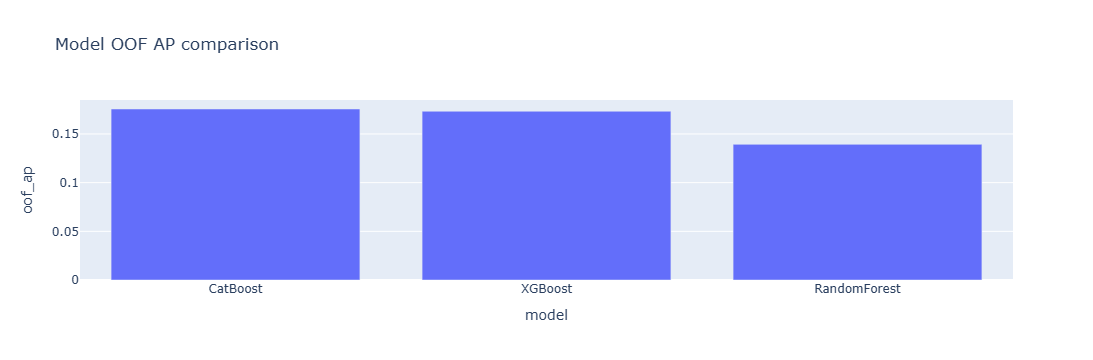

Top-5 XGB trials:
    number     value  params_learning_rate  params_max_depth  \
22      22  0.151200              0.025299                 3   
23      23  0.150674              0.026154                 3   
14      14  0.150175              0.028847                 3   
24      24  0.147843              0.032127                 3   
7        7  0.147463              0.024520                 4   

    params_n_estimators  
22                  765  
23                  689  
14                  768  
24                  661  
7                   367  
Top-5 RF trials:
    number     value  params_n_estimators  params_max_depth
0        0  0.131550                  574                29
24      24  0.131441                  594                22
13      13  0.131024                  400                26
22      22  0.130969                  429                21
23      23  0.130764                  332                28


In [12]:
import plotly.express as px

_ = px.bar(result_df, x="model", y="oof_ap", title="Model OOF AP comparison").show()

print("Top-5 XGB trials:")
print(study_xgb.trials_dataframe()[["number", "value", "params_learning_rate", "params_max_depth", "params_n_estimators"]].sort_values("value", ascending=False).head())

print("Top-5 RF trials:")
print(study_rf.trials_dataframe()[["number", "value", "params_n_estimators", "params_max_depth"]].sort_values("value", ascending=False).head())

if study_cat is not None:
    print("Top-5 CatBoost trials:")
    print(study_cat.trials_dataframe()[["number", "value", "params_learning_rate", "params_depth", "params_iterations"]].sort_values("value", ascending=False).head())

## 12) 앙상블 구성 (가중 평균) 및 최종 예측값 생성

In [13]:
oof_stack = np.vstack([xgb_oof, rf_oof, cat_oof]).T
test_stack = np.vstack([xgb_test, rf_test, cat_test]).T


def ens_objective(trial):
    w1 = trial.suggest_float("w_xgb", 0.0, 1.0)
    w2 = trial.suggest_float("w_rf", 0.0, 1.0)
    w3 = trial.suggest_float("w_cat", 0.0, 1.0)
    s = w1 + w2 + w3 + 1e-12
    w = np.array([w1, w2, w3]) / s
    pred = (oof_stack * w).sum(axis=1)
    return ap_score(y, pred)


study_ens = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_ens.optimize(ens_objective, n_trials=200, show_progress_bar=False)

w_raw = np.array([
    study_ens.best_trial.params["w_xgb"],
    study_ens.best_trial.params["w_rf"],
    study_ens.best_trial.params["w_cat"],
], dtype=np.float64)
weights = w_raw / (w_raw.sum() + 1e-12)

ens_oof = (oof_stack * weights).sum(axis=1)
ens_test = (test_stack * weights).sum(axis=1)
ens_oof_ap = ap_score(y, ens_oof)

print("ensemble weights [xgb, rf, cat]:", weights)
print(f"ensemble OOF AP: {ens_oof_ap:.6f}")

[I 2026-03-27 02:38:26,200] A new study created in memory with name: no-name-b5d2edbf-a28e-4f7e-9a85-b53e3366beb6
[I 2026-03-27 02:38:26,361] Trial 0 finished with value: 0.1535673688360605 and parameters: {'w_xgb': 0.3745401188473625, 'w_rf': 0.9507143064099162, 'w_cat': 0.7319939418114051}. Best is trial 0 with value: 0.1535673688360605.
[I 2026-03-27 02:38:26,526] Trial 1 finished with value: 0.16347966138287687 and parameters: {'w_xgb': 0.5986584841970366, 'w_rf': 0.15601864044243652, 'w_cat': 0.15599452033620265}. Best is trial 1 with value: 0.16347966138287687.
[I 2026-03-27 02:38:26,798] Trial 2 finished with value: 0.15089315686596524 and parameters: {'w_xgb': 0.05808361216819946, 'w_rf': 0.8661761457749352, 'w_cat': 0.6011150117432088}. Best is trial 1 with value: 0.16347966138287687.
[I 2026-03-27 02:38:27,022] Trial 3 finished with value: 0.17496090885672838 and parameters: {'w_xgb': 0.7080725777960455, 'w_rf': 0.020584494295802447, 'w_cat': 0.9699098521619943}. Best is tria

ensemble weights [xgb, rf, cat]: [1.75069350e-01 5.03529727e-04 8.24427120e-01]
ensemble OOF AP: 0.175762


## 13) best_final 결과 저장 (모델/예측/리포트)

In [14]:
# submission
sample_sub = pd.read_csv(SAMPLE_SUB_PATH)
if "fraud_bool" in sample_sub.columns:
    sub_col = "fraud_bool"
else:
    sub_col = sample_sub.columns[-1]

submission = sample_sub.copy()
submission[sub_col] = ens_test
submission_path = DATA_DIR / "submission_best_final_ensemble.csv"
submission.to_csv(submission_path, index=False)

# refit full models for artifact saving
xgb_full = xgb.XGBClassifier(**best_xgb_params)
xgb_full.fit(X, y, verbose=False)

rf_full = RandomForestClassifier(**best_rf_params)
rf_full.fit(X, y)

cat_full = CatBoostClassifier(**cat_params)
cat_full.fit(X, y, verbose=False)

joblib.dump(xgb_full, DATA_DIR / "best_final_xgb.joblib")
joblib.dump(rf_full, DATA_DIR / "best_final_rf.joblib")
joblib.dump(cat_full, DATA_DIR / "best_final_catboost.joblib")

with open(DATA_DIR / "best_final_preprocess_meta.json", "w", encoding="utf-8") as f:
    json.dump(preprocess_meta, f, ensure_ascii=False, indent=2)

report = {
    "seed": SEED,
    "scores": {
        "xgb_oof_ap": float(xgb_oof_ap),
        "rf_oof_ap": float(rf_oof_ap),
        "cat_oof_ap": float(cat_oof_ap),
        "ensemble_oof_ap": float(ens_oof_ap),
    },
    "ensemble_weights": {
        "xgb": float(weights[0]),
        "rf": float(weights[1]),
        "cat": float(weights[2]),
    },
    "best_params": {
        "xgb": best_xgb_params,
        "rf": best_rf_params,
        "cat": cat_params,
    },
    "files": {
        "submission": str(submission_path),
        "xgb_model": "best_final_xgb.joblib",
        "rf_model": "best_final_rf.joblib",
        "cat_model": "best_final_catboost.joblib",
        "preprocess_meta": "best_final_preprocess_meta.json",
    },
}

with open(DATA_DIR / "best_final_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("saved:")
print(" -", submission_path)
print(" - best_final_xgb.joblib")
print(" - best_final_rf.joblib")
print(" - best_final_catboost.joblib")
print(" - best_final_preprocess_meta.json")
print(" - best_final_report.json")

result_df

saved:
 - submission_best_final_ensemble.csv
 - best_final_xgb.joblib
 - best_final_rf.joblib
 - best_final_catboost.joblib
 - best_final_preprocess_meta.json
 - best_final_report.json


,model,oof_ap,cv_mean,cv_std
0,CatBoost,0.175646,0.176656,0.006838
1,XGBoost,0.173335,0.174209,0.005574
2,RandomForest,0.139331,0.140179,0.007963
